# Example of the aitlas toolbox in the context of multi label image classification

## Import the required packages

In [2]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import MultiSceneDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/multiscene/images/",
    "csv_file": "./data/multiscene/labels.csv",
}
dataset = MultiSceneDataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 100000


## Show images from the dataset

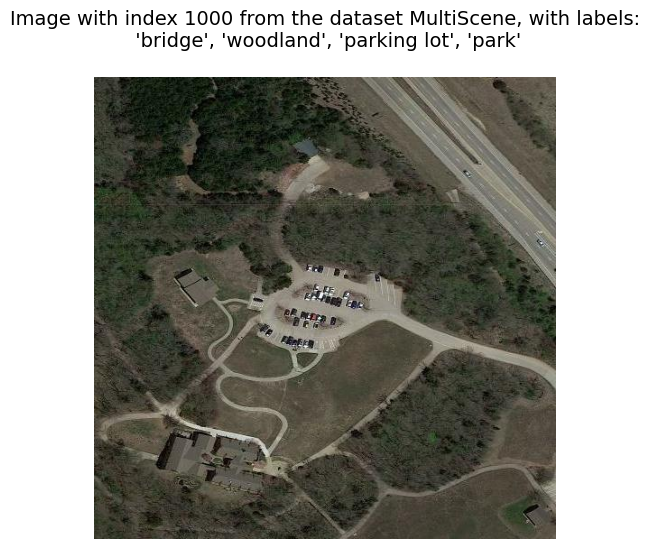

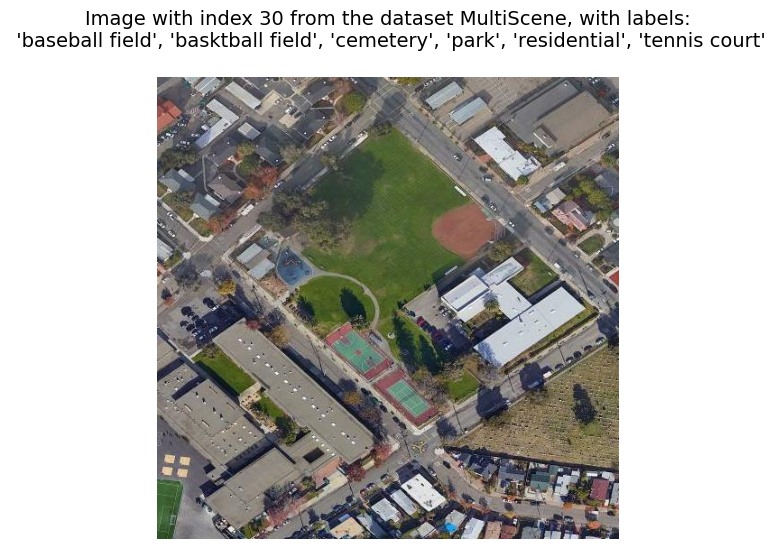

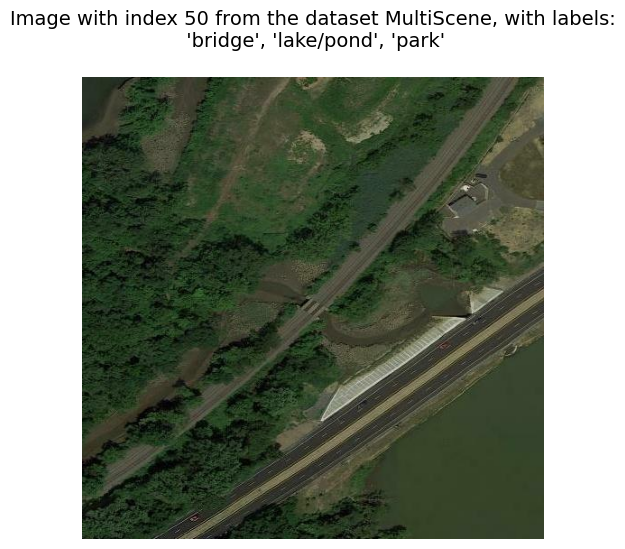

In [9]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(50)

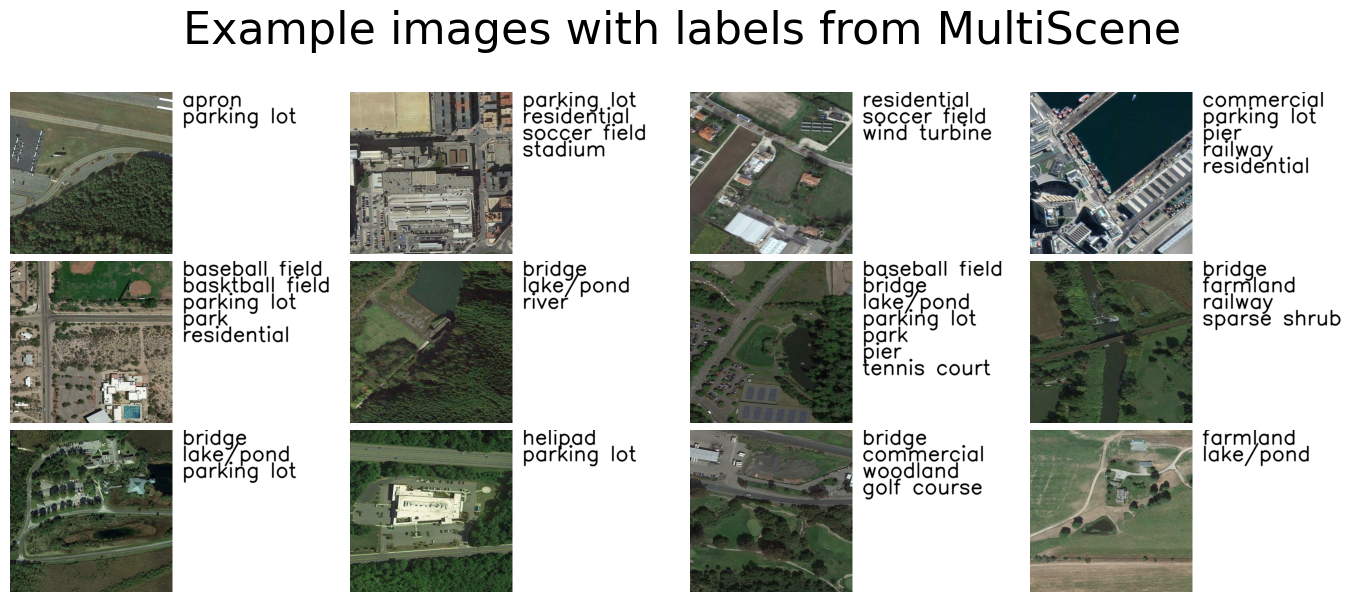

In [58]:
fig4 = dataset.show_batch(12)

## Inspect the data

In [62]:
dataset.show_samples()

,IMAGE\LABEL,Apron,BaseballField,BasketballField,Beach,Bridge,Cemetery,Commercial,Farmland,Woodland,...,SolarPannel,SparseShrub,Stadium,StorageTank,TennisCourt,TrainStation,WastewaterPlant,WindTrubine,Works,Sea
0,img_1,0,0,0,0,1,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
1,img_2,0,0,0,0,1,0,0,1,0,...,0,0,1,0,0,0,0,0,0,0
2,img_3,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
3,img_4,0,0,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,img_5,0,0,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
5,img_6,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
6,img_7,0,0,0,0,1,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
7,img_8,0,0,0,0,1,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
8,img_9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,img_10,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [66]:
dataset.data_distribution_table()

,Label,Count
1,Apron,2116
2,BaseballField,5039
3,BasketballField,5581
4,Beach,3922
5,Bridge,27358
6,Cemetery,4356
7,Commercial,10505
8,Farmland,22561
9,Woodland,28256
10,GolfCourse,3148


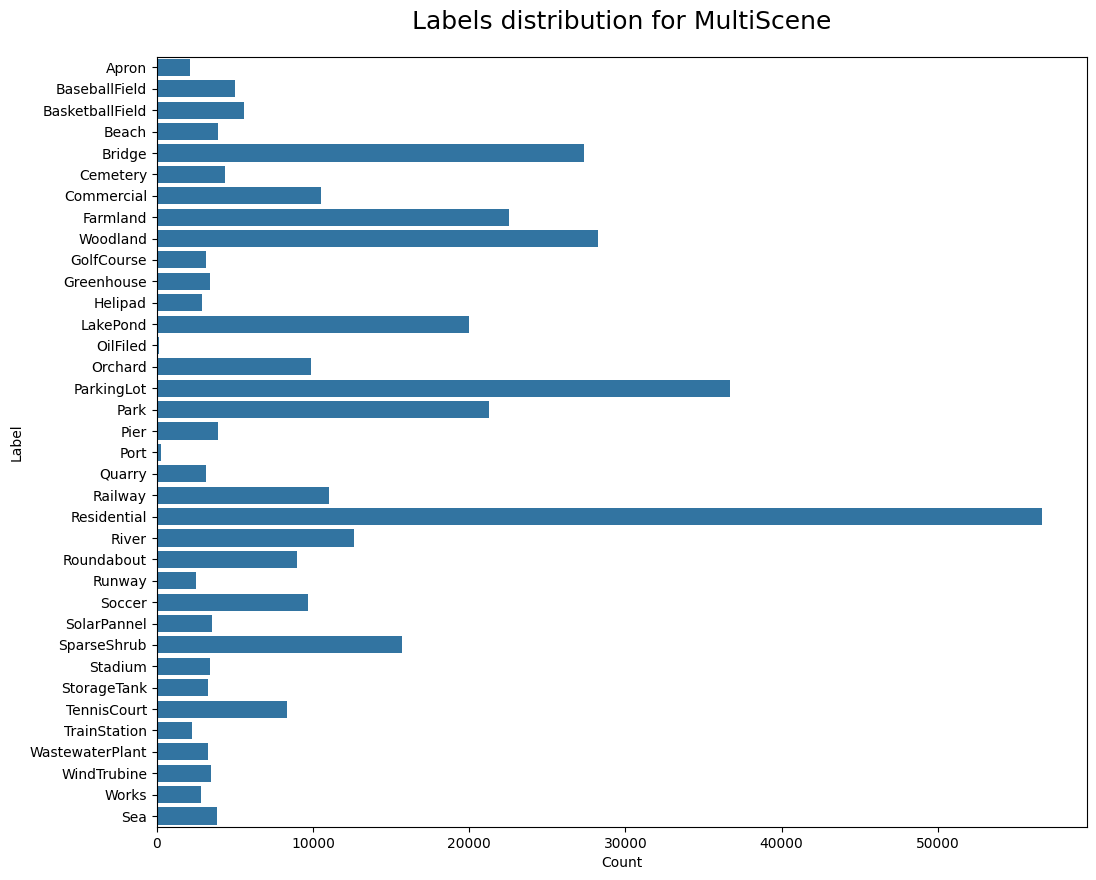

In [67]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

New 60/20/20 splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/multiscene/images/",
    "csv_file": "./data/multiscene/new_splits/multiscene_train.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

train_dataset = MultiSceneDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor() 

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/multiscene/images/",
    "csv_file": "./data/multiscene/new_splits/multiscene_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = MultiSceneDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(93000, 7000)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/multiscene/"
model_config = {
    "num_classes": 36, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5, 
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2025-09-10 10:07:13,417 INFO Starting training.
training: 100%|██████████| 2907/2907 [05:10<00:00,  9.35it/s]
2025-09-10 10:12:24,762 INFO epoch: 1, time: 311, loss:  0.20263
testing on train set: 100%|██████████| 2907/2907 [02:16<00:00, 21.28it/s]
2025-09-10 10:14:42,120 INFO Accuracy:0.9342813620071685, Accuracy per Class:[0.98682796 0.97978495 0.94622581 0.97350538 0.84355914 0.96525806
 0.9034086  0.86216129 0.79846237 0.98330108 0.97498925 0.97876344
 0.85504301 0.99850538 0.93675269 0.78073118 0.83629032 0.97984946
 0.99748387 0.97652688 0.92548387 0.79782796 0.89580645 0.95758065
 0.98151613 0.92219355 0.97543011 0.84195699 0.97205376 0.97270968
 0.95180645 0.98211828 0.97798925 0.9758172  0.97183871 0.97456989], Precision Micro:0.7701889514694483, Precision Macro:0.710040315493928, Precision Weighted:0.7677065588029304, Precision per Class:[0.72633612 0.90046838 0.5559322  0.78254649 0.84165621 0.8314239
 0.66158114 0.70762817 0.69020101 0.82075472 0.78908849 0.8554337
 0.84378

0.11447335812277153

## Predictions

2025-09-10 11:26:23,899 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/multiscene/checkpoint.pth.tar
2025-09-10 11:26:24,179 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/multiscene/checkpoint.pth.tar at epoch 11


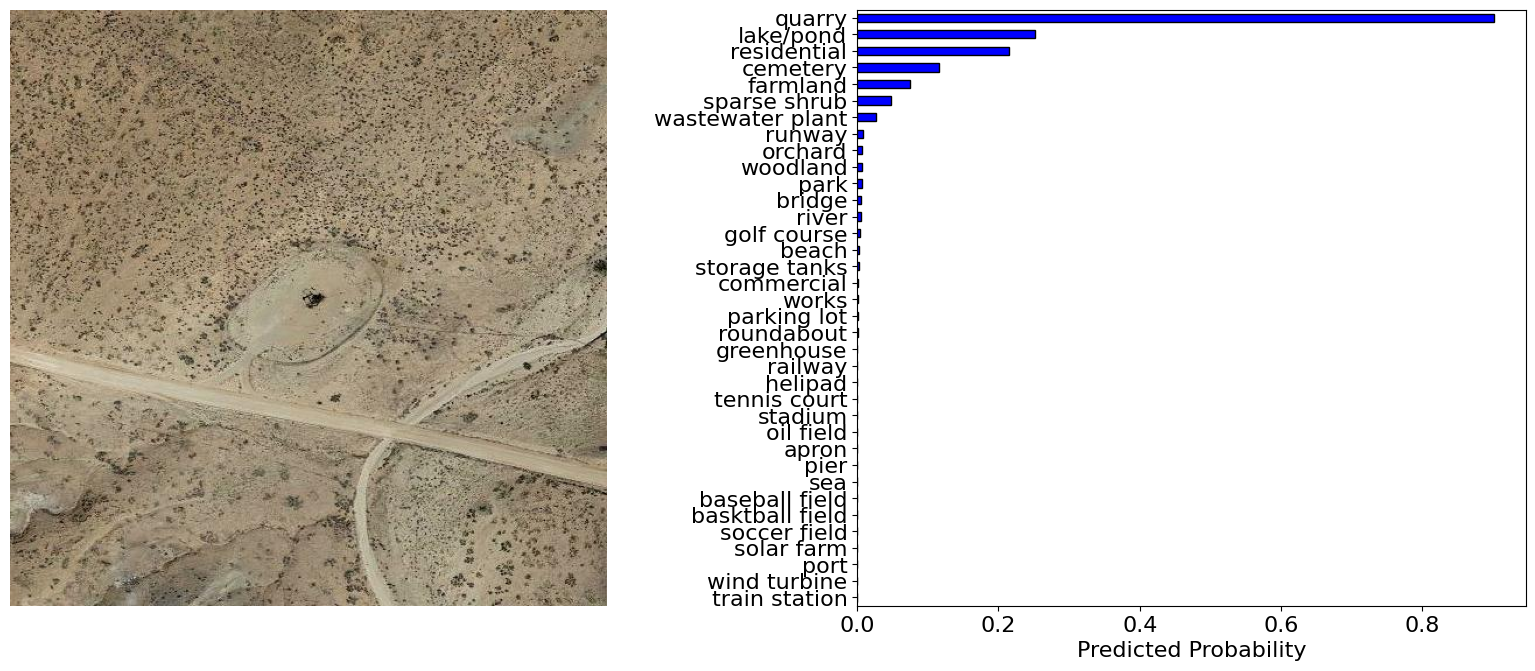

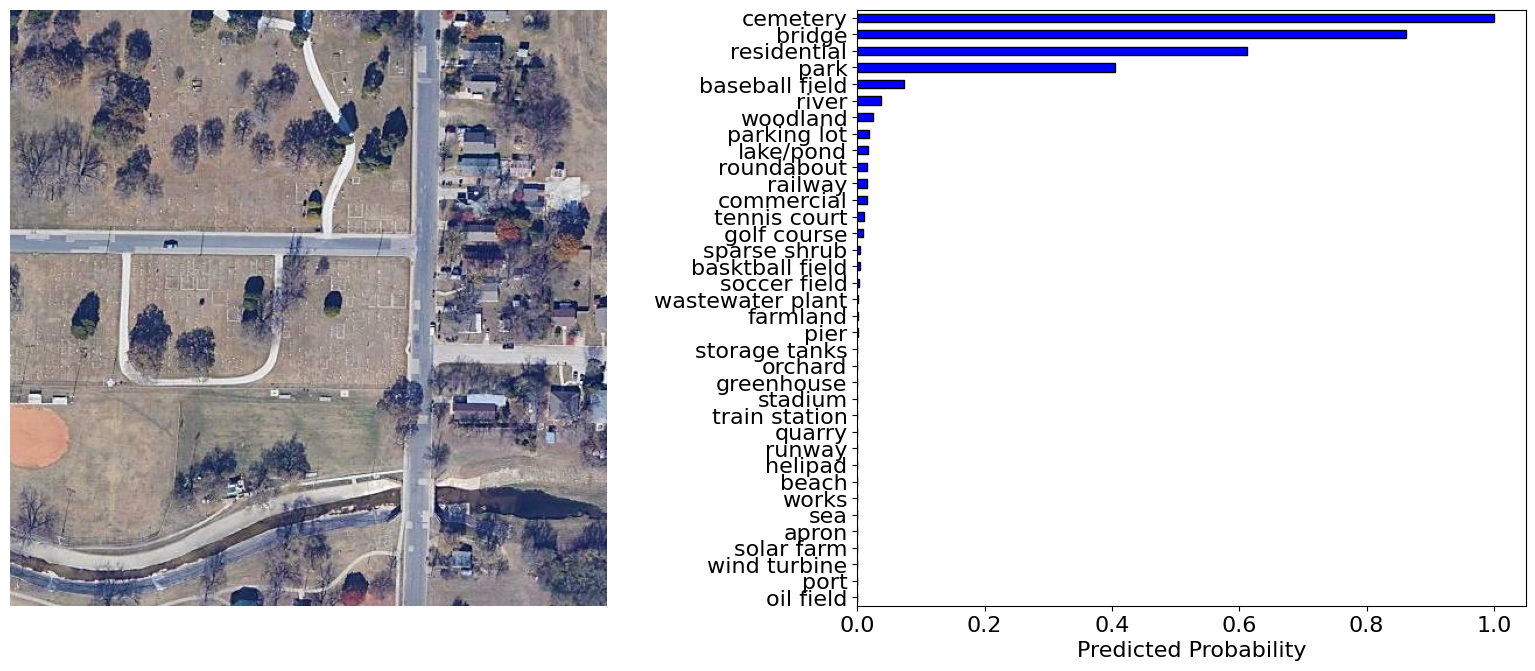

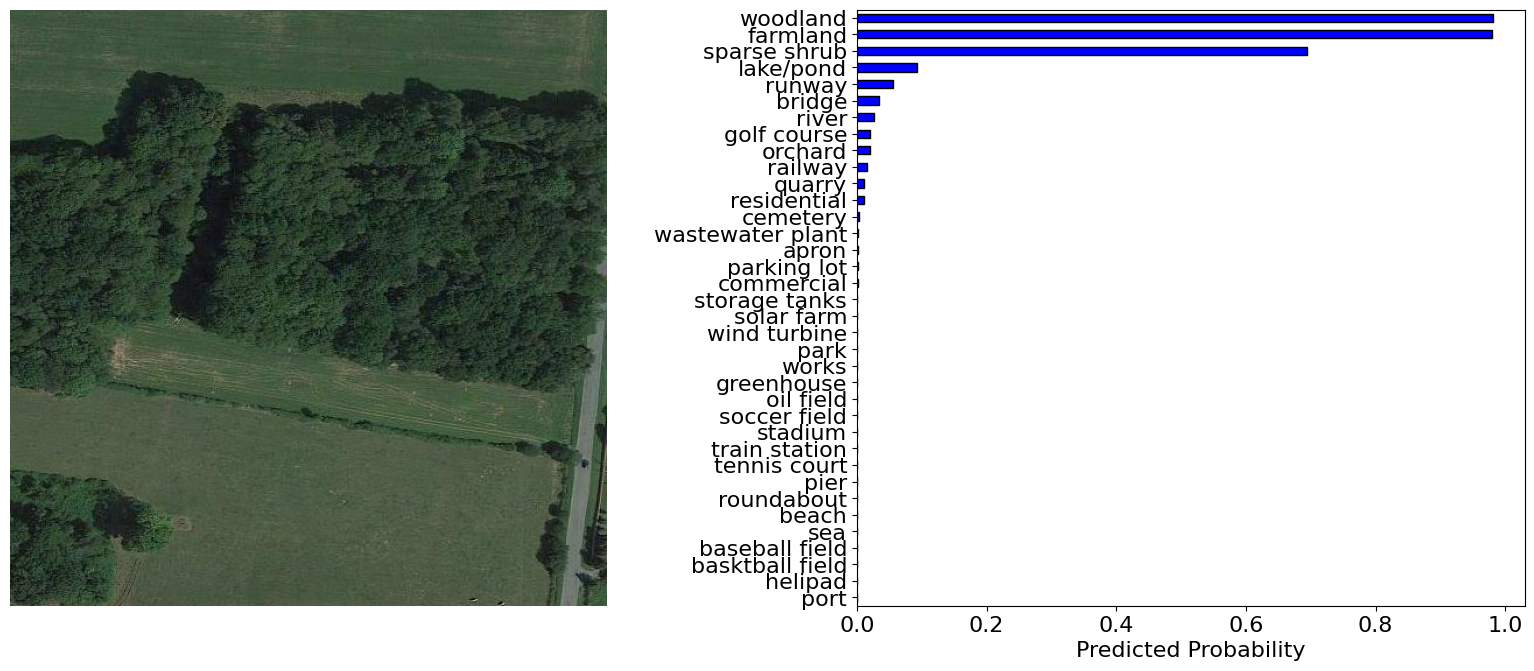

In [ ]:
model_path = "./data/experiments/multiscene/checkpoint.pth.tar"
labels = ["apron","baseball field","basktball field","beach","bridge","cemetery","commercial","farmland",
          "woodland","golf course","greenhouse","helipad","lake/pond","oil field","orchard","parking lot",
          "park","pier","port","quarry","railway","residential","river","roundabout","runway","soccer field",
          "solar farm","sparse shrub","stadium","storage tanks","tennis court","train station","wastewater plant",
          "wind turbine","works","sea"]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader('./data/multiscene/images/img_10590.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/multiscene/images/img_12354.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/multiscene/images/img_2898.jpg')
fig = model.predict_image(image, labels, transform)